# DILI Prediction: Alloriginaldata (clinical) + NCV-888 → Held-out 223
Replicates the 0.762 AUC pipeline using the correct clinical training data.

**Data strategy:**
- **Clinical training**: `Alloriginaldata_19911.csv` minus all Gold Standard 1111 compounds (leakage-free)
- **Augmentation**: `test_data_ncv_DILIst_888.csv` (NCV portion of Gold Standard — Seal 2024 train split)
- **GIN pretraining**: 7 PubChem assays (~307K compounds)
- **Final test**: `test_data_heldouttest_DILIst_223.csv` (true held-out, never seen during training)

In [9]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, ParameterGrid, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    f1_score, confusion_matrix, roc_curve, precision_recall_curve
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GINConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED   = 42
BASE   = '/Users/yaminichitikela/Desktop/qsar casepase'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
np.random.seed(SEED); torch.manual_seed(SEED)
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 3 — Feature Engineering (ECFP4 + Molecular Graphs)

In [12]:
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]
def one_hot(val, choices):
    v = [0]*len(choices)
    try: v[choices.index(val)] = 1
    except ValueError: pass
    return v

def atom_features(atom):
    return (one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [1]
            + one_hot(atom.GetDegree(), [0,1,2,3,4,5])
            + [atom.GetFormalCharge()]
            + one_hot(int(atom.GetHybridization()), [2,3,4,5])
            + [int(atom.GetIsAromatic()), int(atom.IsInRing())])

def bond_features(bond):
    bt = bond.GetBondTypeAsDouble()
    return [bt==1.0, bt==1.5, bt==2.0, bt==3.0,
            int(bond.GetIsConjugated()), int(bond.IsInRing())]

def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    if mol.GetNumBonds() == 0:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0,6), dtype=torch.float)
    else:
        edges, attrs = [], []
        for b in mol.GetBonds():
            i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
            bf = bond_features(b)
            edges += [[i,j],[j,i]]; attrs += [bf,bf]
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(attrs, dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.float))

ATOM_DIM = len(atom_features(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))
print(f'Atom feature dim: {ATOM_DIM}')

Atom feature dim: 23


---
## Step 4 — Load DILI Data (Leakage-Free)

**Critical leakage prevention:**
- Gold Standard 1111 = NCV-888 + held-out-223 (they do not overlap)
- `Alloriginaldata_19911` contains 888 Gold Standard compounds (NCV-888) and 179 held-out-223 compounds
- We remove ALL 1,111 Gold Standard compounds from Alloriginaldata before training
- NCV-888 is then added back as augmentation only (never used for model selection)

In [14]:
# ── Load Gold Standard 1111 (used only to define exclusion set) ───────────
gold_df = pd.read_csv(f'{BASE}/liver/DILI_Goldstandard_1111.csv')
gold_df['csmi'] = gold_df['smiles_r'].apply(canonicalize)
gold_smiles = set(gold_df['csmi'].dropna())
print(f'Gold Standard 1111 exclusion set: {len(gold_smiles):,} compounds')

# ── Load NCV-888 (augmentation — subset of Gold Standard) ─────────────────
ncv_df = pd.read_csv(f'{BASE}/liver/test_data_ncv_DILIst_888.csv',
                     usecols=['smiles_r', 'TOXICITY'])
ncv_df['csmi'] = ncv_df['smiles_r'].apply(canonicalize)
ncv_df = ncv_df.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)
ncv_df = ncv_df[['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'})
print(f'NCV-888 (augmentation): {len(ncv_df):,}  DILI+={ncv_df.label.sum():,}  DILI-={(ncv_df.label==0).sum():,}')

# ── Load held-out 223 (final test — NEVER used for training or selection) ─
held_df = pd.read_csv(f'{BASE}/liver/test_data_heldouttest_DILIst_223.csv',
                      usecols=['smiles_r', 'TOXICITY'])
held_df['csmi'] = held_df['smiles_r'].apply(canonicalize)
held_df = held_df.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)
held_df = held_df[['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'})
held_smiles = set(held_df['csmi'])
print(f'Held-out 223 (test):    {len(held_df):,}  DILI+={held_df.label.sum():,}  DILI-={(held_df.label==0).sum():,}')

# ── Load Alloriginaldata — remove ALL Gold Standard compounds ──────────────
alldata = pd.read_csv(f'{BASE}/liver/Alloriginaldata_19911.csv')
alldata['csmi'] = alldata['smiles_r'].apply(canonicalize)
alldata = alldata.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)

# Safety check: how much leakage existed
overlap_held = alldata['csmi'].isin(held_smiles).sum()
overlap_gold = alldata['csmi'].isin(gold_smiles).sum()
print(f'\nLeakage in Alloriginaldata before cleaning:')
print(f'  ∩ held-out-223 : {overlap_held:,} (would have been test leakage!)')
print(f'  ∩ Gold-1111    : {overlap_gold:,} (includes NCV-888)')

# Remove ALL Gold Standard compounds (covers both NCV-888 and held-out-223)
clin_df = alldata[~alldata['csmi'].isin(gold_smiles)].reset_index(drop=True)
clin_df = clin_df[['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'})
print(f'\nClinical training pool (Alloriginal minus Gold-1111): {len(clin_df):,}')
print(f'  DILI+: {clin_df.label.sum():,}  DILI-: {(clin_df.label==0).sum():,}  ratio={(clin_df.label==0).sum()/clin_df.label.sum():.1f}:1')

Gold Standard 1111 exclusion set: 1,096 compounds
NCV-888 (augmentation): 874  DILI+=553  DILI-=321
Held-out 223 (test):    222  DILI+=155  DILI-=67

Leakage in Alloriginaldata before cleaning:
  ∩ held-out-223 : 179 (would have been test leakage!)
  ∩ Gold-1111    : 888 (includes NCV-888)

Clinical training pool (Alloriginal minus Gold-1111): 12,900
  DILI+: 4,217  DILI-: 8,683  ratio=2.1:1


In [15]:
def build_features(df, name):
    """Build ECFP4 + graph features. Returns (cleaned_df, X, y, graphs)."""
    fps = df['csmi'].apply(smiles_to_ecfp4)
    ok  = fps.notna().values
    df  = df[ok].reset_index(drop=True)
    X   = np.vstack(fps[ok].values)
    y   = df['label'].values.astype(int)
    graphs_raw = [mol_to_graph(smi, int(lbl)) for smi, lbl in zip(df['csmi'], y)]
    g_ok = np.array([g is not None for g in graphs_raw])
    graphs = [g for g, ok2 in zip(graphs_raw, g_ok) if ok2]
    X = X[g_ok]; y = y[g_ok]; df = df[g_ok].reset_index(drop=True)
    print(f'{name}: {len(df):,}  DILI+={int(y.sum()):,}  DILI-={int((y==0).sum()):,}')
    return df, X, y, graphs

print('Building ECFP4 + graph features...')
clin_df,  X_clin,  y_clin,  clin_graphs  = build_features(clin_df,  'Clinical (Alloriginal - Gold)')
ncv_df,   X_ncv,   y_ncv,   ncv_graphs   = build_features(ncv_df,   'NCV-888 (augmentation)')
held_df,  X_held,  y_held,  held_graphs  = build_features(held_df,  'Held-out-223 (test)')

held_loader = DataLoader(held_graphs, batch_size=64)
print('\nAll features ready.')

Building ECFP4 + graph features...
Clinical (Alloriginal - Gold): 12,900  DILI+=4,217  DILI-=8,683
NCV-888 (augmentation): 874  DILI+=553  DILI-=321
Held-out-223 (test): 222  DILI+=155  DILI-=67

All features ready.


---
## Step 5 — Evaluation Helper

In [16]:
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'F1'         : round(f1_score(y_true, y_pred),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','Sensitivity','Specificity','CCR','ROC-AUC','PR-AUC','MCC','F1']
print('Evaluation helper ready.')

Evaluation helper ready.


---
## Step 6 — Train RF + XGB on Clinical Data (Alloriginal - Gold)

In [17]:
# 80/10/10 split of clinical data
idx_c = np.arange(len(y_clin))
idx_c_pool, idx_c_te = train_test_split(
    idx_c, test_size=0.10, stratify=y_clin, random_state=SEED)
idx_c_tr, idx_c_va = train_test_split(
    idx_c_pool, test_size=0.10/(0.80+0.10), stratify=y_clin[idx_c_pool], random_state=SEED)

X_c_tr, y_c_tr = X_clin[idx_c_tr], y_clin[idx_c_tr]
X_c_va, y_c_va = X_clin[idx_c_va], y_clin[idx_c_va]

print(f'Clinical split (for model selection only — final test = held-out-223):')
print(f'  Train : {len(idx_c_tr):,}  DILI+={y_c_tr.sum():,}  DILI-={(y_c_tr==0).sum():,}')
print(f'  Val   : {len(idx_c_va):,}  DILI+={y_c_va.sum():,}  DILI-={(y_c_va==0).sum():,}')

# DataLoaders for GIN fine-tuning
g_c_tr = [clin_graphs[i] for i in idx_c_tr]
g_c_va = [clin_graphs[i] for i in idx_c_va]
clin_tr_ld = DataLoader(g_c_tr, batch_size=64, shuffle=True)
clin_va_ld = DataLoader(g_c_va, batch_size=64)

rf_grid = ParameterGrid({
    'n_estimators'    : [300, 500],
    'max_features'    : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
})
xgb_grid = ParameterGrid({
    'n_estimators': [300, 500],
    'max_depth'   : [4, 6],
    'learning_rate': [0.05, 0.1],
})
sw_clin = (y_c_tr == 0).sum() / max((y_c_tr == 1).sum(), 1)

print('\nTraining RF on clinical data...')
best_auc_rf, best_rf = 0, None
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_c_tr, y_c_tr)
    auc = roc_auc_score(y_c_va, clf.predict_proba(X_c_va)[:, 1])
    if auc > best_auc_rf: best_auc_rf, best_rf = auc, clf
print(f'  RF  val AUC={best_auc_rf:.4f}')

print('Training XGB on clinical data...')
best_auc_xgb, best_xgb = 0, None
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw_clin, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_c_tr, y_c_tr)
    auc = roc_auc_score(y_c_va, clf.predict_proba(X_c_va)[:, 1])
    if auc > best_auc_xgb: best_auc_xgb, best_xgb = auc, clf
print(f'  XGB val AUC={best_auc_xgb:.4f}')

Clinical split (for model selection only — final test = held-out-223):
  Train : 10,320  DILI+=3,373  DILI-=6,947
  Val   : 1,290  DILI+=422  DILI-=868

Training RF on clinical data...
  RF  val AUC=0.7436
Training XGB on clinical data...
  XGB val AUC=0.7447


---
## Step 7 — Transfer Learning: Pretrain GIN on Assays → Fine-tune on Clinical Data
- **Stage 1**: Pretrain GIN encoder on ~307K assay compounds
- **Stage 2**: Gradual unfreezing fine-tune on clinical training set (ULMFiT / Géron HOML Ch.11)

In [18]:
class GNNEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden     = hidden
        self.dropout    = dropout
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
            self.convs.append(GINConv(mlp))
            self.bns.append(nn.BatchNorm1d(hidden))

    def forward(self, data):
        x, ei, batch = data.x, data.edge_index, data.batch
        h = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.relu(conv(h, ei)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

class ClassHead(nn.Module):
    def __init__(self, hidden=256, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, h):
        return self.net(h).squeeze(-1)

HIDDEN, N_LAYERS = 256, 4

def get_probs(encoder, head, loader, device):
    encoder.eval(); head.eval()
    probs, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs.extend(torch.sigmoid(head(encoder(batch))).cpu().numpy())
            labels.extend(batch.y.cpu().numpy())
    return np.array(probs), np.array(labels)

print(f'GNNEncoder + ClassHead defined.')

GNNEncoder + ClassHead defined.


In [19]:
# Assay pretrain/val split
idx_ap = np.arange(len(assay_graphs))
idx_ap_tr, idx_ap_va = train_test_split(
    idx_ap, test_size=0.10, stratify=y_assay_all, random_state=SEED)
assay_tr_ld = DataLoader([assay_graphs[i] for i in idx_ap_tr], batch_size=512, shuffle=True)
assay_va_ld = DataLoader([assay_graphs[i] for i in idx_ap_va], batch_size=512)
print(f'Assay pretrain/val: {len(idx_ap_tr):,} / {len(idx_ap_va):,}')

encoder    = GNNEncoder(ATOM_DIM, hidden=HIDDEN, n_layers=N_LAYERS).to(DEVICE)
assay_head = ClassHead(hidden=HIDDEN).to(DEVICE)

pos_w_assay = torch.tensor(
    [(y_assay_all[idx_ap_tr]==0).sum() / max((y_assay_all[idx_ap_tr]==1).sum(),1)],
    dtype=torch.float).to(DEVICE)
crit_pre = nn.BCEWithLogitsLoss(pos_weight=pos_w_assay)
opt_pre  = torch.optim.Adam(
    list(encoder.parameters()) + list(assay_head.parameters()), lr=1e-3)
sched_pre = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_pre, patience=5, factor=0.5)

PRETRAIN_EPOCHS, PRETRAIN_PATIENCE = 50, 10
best_pre_auc, best_enc_state, no_imp_pre = 0, None, 0

print('=== Stage 1: Pretraining GIN on assay compounds ===')
for ep in range(PRETRAIN_EPOCHS):
    encoder.train(); assay_head.train()
    for batch in assay_tr_ld:
        batch = batch.to(DEVICE)
        opt_pre.zero_grad()
        crit_pre(assay_head(encoder(batch)), batch.y).backward()
        opt_pre.step()
    pre_probs, pre_labels = get_probs(encoder, assay_head, assay_va_ld, DEVICE)
    va_auc = roc_auc_score(pre_labels, pre_probs)
    sched_pre.step(1 - va_auc)
    if va_auc > best_pre_auc:
        best_pre_auc = va_auc; best_enc_state = copy.deepcopy(encoder.state_dict()); no_imp_pre = 0
    else:
        no_imp_pre += 1
        if no_imp_pre >= PRETRAIN_PATIENCE:
            print(f'  Early stop ep {ep+1}  bes t_val={best_pre_auc:.4f}'); break
    if (ep+1) % 10 == 0: print(f'  Ep {ep+1:3d}  val_AUC={va_auc:.4f}  best={best_pre_auc:.4f}')

encoder.load_state_dict(best_enc_state)
print(f'Pretraining done. Best val AUC = {best_pre_auc:.4f}')

Assay pretrain/val: 276,879 / 30,765
=== Stage 1: Pretraining GIN on assay compounds ===
  Ep  10  val_AUC=0.8817  best=0.8817
  Ep  20  val_AUC=0.8898  best=0.8965
  Ep  30  val_AUC=0.9052  best=0.9060
  Ep  40  val_AUC=0.9138  best=0.9138
  Ep  50  val_AUC=0.9160  best=0.9160
Pretraining done. Best val AUC = 0.9160


In [20]:
dili_head = ClassHead(hidden=HIDDEN).to(DEVICE)

pos_w_clin = torch.tensor(
    [(y_c_tr==0).sum() / max((y_c_tr==1).sum(),1)],
    dtype=torch.float).to(DEVICE)
crit_ft = nn.BCEWithLogitsLoss(pos_weight=pos_w_clin)

global_best_auc, global_best_enc, global_best_head = 0.0, None, None

def ft_phase(phase_name, trainable_params, n_epochs, lr, patience=8):
    global global_best_auc, global_best_enc, global_best_head
    opt   = torch.optim.Adam(trainable_params, lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    no_imp = 0
    print(f'\n--- {phase_name}  (lr={lr:.0e}, max {n_epochs} ep) ---')
    for ep in range(n_epochs):
        encoder.train(); dili_head.train()
        for batch in clin_tr_ld:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            crit_ft(dili_head(encoder(batch)), batch.y).backward()
            opt.step()
        va_p, va_l = get_probs(encoder, dili_head, clin_va_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > global_best_auc:
            global_best_auc  = va_auc
            global_best_enc  = copy.deepcopy(encoder.state_dict())
            global_best_head = copy.deepcopy(dili_head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience: break
    print(f'    best_global_val_AUC={global_best_auc:.4f}')

# Phase 0: freeze encoder, train head only
for p in encoder.parameters(): p.requires_grad = False
for p in dili_head.parameters(): p.requires_grad = True
ft_phase('Phase 0 — head only (encoder frozen)', list(dili_head.parameters()), 20, 1e-3)

# Phase 1: unfreeze top GIN layer
for p in encoder.convs[3].parameters(): p.requires_grad = True
for p in encoder.bns[3].parameters():   p.requires_grad = True
ft_phase('Phase 1 — unfreeze convs[3]',
         [p for p in list(encoder.parameters())+list(dili_head.parameters()) if p.requires_grad],
         20, 5e-4)

# Phase 2
for p in encoder.convs[2].parameters(): p.requires_grad = True
for p in encoder.bns[2].parameters():   p.requires_grad = True
ft_phase('Phase 2 — unfreeze convs[2]',
         [p for p in list(encoder.parameters())+list(dili_head.parameters()) if p.requires_grad],
         20, 1e-4)

# Phase 3
for p in encoder.convs[1].parameters(): p.requires_grad = True
for p in encoder.bns[1].parameters():   p.requires_grad = True
ft_phase('Phase 3 — unfreeze convs[1]',
         [p for p in list(encoder.parameters())+list(dili_head.parameters()) if p.requires_grad],
         15, 5e-5)

# Phase 4: unfreeze all
for p in encoder.parameters(): p.requires_grad = True
ft_phase('Phase 4 — unfreeze all',
         list(encoder.parameters())+list(dili_head.parameters()), 15, 1e-5)

encoder.load_state_dict(global_best_enc)
dili_head.load_state_dict(global_best_head)
print(f'\nFine-tuning done. Best val AUC = {global_best_auc:.4f}')


--- Phase 0 — head only (encoder frozen)  (lr=1e-03, max 20 ep) ---
    best_global_val_AUC=0.7040

--- Phase 1 — unfreeze convs[3]  (lr=5e-04, max 20 ep) ---
    best_global_val_AUC=0.7348

--- Phase 2 — unfreeze convs[2]  (lr=1e-04, max 20 ep) ---
    best_global_val_AUC=0.7389

--- Phase 3 — unfreeze convs[1]  (lr=5e-05, max 15 ep) ---
    best_global_val_AUC=0.7389

--- Phase 4 — unfreeze all  (lr=1e-05, max 15 ep) ---
    best_global_val_AUC=0.7408

Fine-tuning done. Best val AUC = 0.7408


---
## Step 8 — Baseline: Clinical-Only Models on Held-out 223

In [21]:
print('=== Baseline: clinical-only models on held-out 223 ===')
print(f'{"Model":<30}  {"AUC":>6}  {"CCR":>5}  {"Sens":>5}  {"Spec":>5}  {"MCC":>6}')
print('-'*62)

base_probs = {}

p_rf = best_rf.predict_proba(X_held)[:, 1]
r_rf = evaluate(y_held, p_rf, 'RF-clin (no aug)')
base_probs['RF-clin'] = p_rf
print(f'{"RF-clin (no aug)":<30}  {r_rf["ROC-AUC"]:>6.4f}  {r_rf["CCR"]:>4.1f}%  '
      f'{r_rf["Sensitivity"]:>4.1f}%  {r_rf["Specificity"]:>4.1f}%  {r_rf["MCC"]:>6.4f}')

p_xgb = best_xgb.predict_proba(X_held)[:, 1]
r_xgb = evaluate(y_held, p_xgb, 'XGB-clin (no aug)')
base_probs['XGB-clin'] = p_xgb
print(f'{"XGB-clin (no aug)":<30}  {r_xgb["ROC-AUC"]:>6.4f}  {r_xgb["CCR"]:>4.1f}%  '
      f'{r_xgb["Sensitivity"]:>4.1f}%  {r_xgb["Specificity"]:>4.1f}%  {r_xgb["MCC"]:>6.4f}')

p_gin, _ = get_probs(encoder, dili_head, held_loader, DEVICE)
r_gin = evaluate(y_held, p_gin, 'TL-GIN (no aug)')
base_probs['TL-GIN'] = p_gin
print(f'{"TL-GIN (no aug)":<30}  {r_gin["ROC-AUC"]:>6.4f}  {r_gin["CCR"]:>4.1f}%  '
      f'{r_gin["Sensitivity"]:>4.1f}%  {r_gin["Specificity"]:>4.1f}%  {r_gin["MCC"]:>6.4f}')

p_cons = np.mean([p_rf, p_xgb, p_gin], axis=0)
r_cons = evaluate(y_held, p_cons, 'Consensus (no aug)')
base_probs['Consensus'] = p_cons
print(f'{"Consensus (no aug)":<30}  {r_cons["ROC-AUC"]:>6.4f}  {r_cons["CCR"]:>4.1f}%  '
      f'{r_cons["Sensitivity"]:>4.1f}%  {r_cons["Specificity"]:>4.1f}%  {r_cons["MCC"]:>6.4f}')

=== Baseline: clinical-only models on held-out 223 ===
Model                              AUC    CCR   Sens   Spec     MCC
--------------------------------------------------------------
RF-clin (no aug)                0.6711  64.9%  52.3%  77.6%  0.2768
XGB-clin (no aug)               0.6580  63.2%  65.2%  61.2%  0.2445
TL-GIN (no aug)                 0.6485  59.0%  65.8%  52.2%  0.1693
Consensus (no aug)              0.6843  62.7%  61.3%  64.2%  0.2344


---
## Step 9 — Augmented Training: Clinical + NCV-888 → Held-out 223
Add NCV-888 to the clinical training set and retrain RF + XGB.
This mirrors the Seal 2024 augmentation step that achieved AUC=0.762.

In [22]:
# Augment: clinical train + NCV-888
X_aug = np.vstack([X_c_tr, X_ncv])
y_aug = np.concatenate([y_c_tr, y_ncv])
print(f'Augmented set: {len(X_aug):,} = clin-train {len(X_c_tr):,} + NCV-888 {len(X_ncv):,}')
print(f'  DILI+={y_aug.sum():,}  DILI-={(y_aug==0).sum():,}')

print('\nTraining RF-aug...')
best_auc_rf_aug, best_rf_aug = 0, None
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_aug, y_aug)
    auc = roc_auc_score(y_c_va, clf.predict_proba(X_c_va)[:, 1])
    if auc > best_auc_rf_aug: best_auc_rf_aug, best_rf_aug = auc, clf
print(f'  RF-aug  val AUC={best_auc_rf_aug:.4f}')

print('Training XGB-aug...')
sw_aug = (y_aug==0).sum() / max((y_aug==1).sum(), 1)
best_auc_xgb_aug, best_xgb_aug = 0, None
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw_aug, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_aug, y_aug)
    auc = roc_auc_score(y_c_va, clf.predict_proba(X_c_va)[:, 1])
    if auc > best_auc_xgb_aug: best_auc_xgb_aug, best_xgb_aug = auc, clf
print(f'  XGB-aug val AUC={best_auc_xgb_aug:.4f}')

print(f'\n{"="*68}')
print('AUGMENTED EVALUATION — held-out 223')
print(f'{"="*68}')
print(f'{"Model":<30}  {"AUC":>6}  {"CCR":>5}  {"Sens":>5}  {"Spec":>5}  {"MCC":>6}')
print('-'*62)

aug_probs = {}

p_rf_aug  = best_rf_aug.predict_proba(X_held)[:, 1]
r_rf_aug  = evaluate(y_held, p_rf_aug, 'RF-aug (+NCV-888)')
aug_probs['RF-aug'] = p_rf_aug
print(f'{"RF-aug (+NCV-888)":<30}  {r_rf_aug["ROC-AUC"]:>6.4f}  {r_rf_aug["CCR"]:>4.1f}%  '
      f'{r_rf_aug["Sensitivity"]:>4.1f}%  {r_rf_aug["Specificity"]:>4.1f}%  {r_rf_aug["MCC"]:>6.4f}')

p_xgb_aug = best_xgb_aug.predict_proba(X_held)[:, 1]
r_xgb_aug = evaluate(y_held, p_xgb_aug, 'XGB-aug (+NCV-888)')
aug_probs['XGB-aug'] = p_xgb_aug
print(f'{"XGB-aug (+NCV-888)":<30}  {r_xgb_aug["ROC-AUC"]:>6.4f}  {r_xgb_aug["CCR"]:>4.1f}%  '
      f'{r_xgb_aug["Sensitivity"]:>4.1f}%  {r_xgb_aug["Specificity"]:>4.1f}%  {r_xgb_aug["MCC"]:>6.4f}')

p_cons_aug = np.mean([p_rf_aug, p_xgb_aug, p_gin], axis=0)
r_cons_aug = evaluate(y_held, p_cons_aug, 'Consensus-aug')
aug_probs['Consensus-aug'] = p_cons_aug
print(f'{"Consensus-aug":<30}  {r_cons_aug["ROC-AUC"]:>6.4f}  {r_cons_aug["CCR"]:>4.1f}%  '
      f'{r_cons_aug["Sensitivity"]:>4.1f}%  {r_cons_aug["Specificity"]:>4.1f}%  {r_cons_aug["MCC"]:>6.4f}')

Augmented set: 11,194 = clin-train 10,320 + NCV-888 874
  DILI+=3,926  DILI-=7,268

Training RF-aug...
  RF-aug  val AUC=0.7451
Training XGB-aug...
  XGB-aug val AUC=0.7438

AUGMENTED EVALUATION — held-out 223
Model                              AUC    CCR   Sens   Spec     MCC
--------------------------------------------------------------
RF-aug (+NCV-888)               0.6855  64.1%  53.5%  74.6%  0.2600
XGB-aug (+NCV-888)              0.6738  65.0%  65.8%  64.2%  0.2778
Consensus-aug                   0.6919  63.1%  61.9%  64.2%  0.2405


---
## Step 10 — Stacking Ensemble (RF-aug + XGB-aug + TL-GIN)

In [23]:
from sklearn.model_selection import StratifiedKFold

# Build OOF predictions on combined train+val pool
X_tv = np.vstack([X_aug, X_c_va])
y_tv = np.concatenate([y_aug, y_c_va])

# Graph list matching X_tv order: aug graphs + val graphs
ncv_graphs_list = ncv_graphs  # already ordered same as X_ncv
tv_graphs = g_c_tr + ncv_graphs_list + g_c_va
print(f'Stacking trainval: {len(X_tv):,}  (aug {len(X_aug):,} + val {len(X_c_va):,})')

SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_rf  = np.zeros(len(X_tv))
oof_xgb = np.zeros(len(X_tv))
oof_gin = np.zeros(len(X_tv))

for fold, (tr_i, va_i) in enumerate(SKF.split(X_tv, y_tv)):
    sw_f = (y_tv[tr_i]==0).sum() / max((y_tv[tr_i]==1).sum(),1)
    rf_f = RandomForestClassifier(n_estimators=300, max_features='sqrt',
                                   class_weight='balanced', n_jobs=-1, random_state=SEED)
    rf_f.fit(X_tv[tr_i], y_tv[tr_i])
    oof_rf[va_i] = rf_f.predict_proba(X_tv[va_i])[:, 1]

    xgb_f = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                           scale_pos_weight=sw_f, eval_metric='logloss',
                           n_jobs=-1, random_state=SEED, verbosity=0)
    xgb_f.fit(X_tv[tr_i], y_tv[tr_i])
    oof_xgb[va_i] = xgb_f.predict_proba(X_tv[va_i])[:, 1]

    fold_g = [tv_graphs[i] for i in va_i if i < len(tv_graphs)]
    if fold_g:
        fp, _ = get_probs(encoder, dili_head, DataLoader(fold_g, batch_size=64), DEVICE)
        oof_gin[va_i[:len(fp)]] = fp
    print(f'  Fold {fold+1}/5 done')

print(f'\nOOF AUCs:  RF={roc_auc_score(y_tv, oof_rf):.4f}  '
      f'XGB={roc_auc_score(y_tv, oof_xgb):.4f}  GIN={roc_auc_score(y_tv, oof_gin):.4f}')

meta_lr = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
meta_lr.fit(np.column_stack([oof_rf, oof_xgb, oof_gin]), y_tv)

meta_held = np.column_stack([p_rf_aug, p_xgb_aug, p_gin])
p_stack   = meta_lr.predict_proba(meta_held)[:, 1]
r_stack   = evaluate(y_held, p_stack, 'Stack (RF+XGB+GIN)')
print(f'\nStack AUC={r_stack["ROC-AUC"]:>6.4f}  CCR={r_stack["CCR"]:>4.1f}%  '
      f'Sens={r_stack["Sensitivity"]:>4.1f}%  Spec={r_stack["Specificity"]:>4.1f}%  MCC={r_stack["MCC"]:>6.4f}')

Stacking trainval: 12,484  (aug 11,194 + val 1,290)
  Fold 1/5 done
  Fold 2/5 done
  Fold 3/5 done
  Fold 4/5 done
  Fold 5/5 done

OOF AUCs:  RF=0.7161  XGB=0.7376  GIN=0.8524

Stack AUC=0.6590  CCR=60.3%  Sens=49.0%  Spec=71.6%  MCC=0.1918


---
## Step 11 — Final Summary & Benchmark vs Seal 2024

=== Final Results on Held-out 223 ===
             Model  Sensitivity  Specificity  CCR  ROC-AUC  PR-AUC    MCC     F1
     Consensus-aug         61.9         64.2 63.1   0.6919  0.8195 0.2405 0.6982
 RF-aug (+NCV-888)         53.5         74.6 64.1   0.6855  0.8222 0.2600 0.6510
Consensus (no aug)         61.3         64.2 62.7   0.6843  0.8103 0.2344 0.6934
XGB-aug (+NCV-888)         65.8         64.2 65.0   0.6738  0.8278 0.2778 0.7260
  RF-clin (no aug)         52.3         77.6 64.9   0.6711  0.8138 0.2768 0.6454
Stack (RF+XGB+GIN)         49.0         71.6 60.3   0.6590  0.7959 0.1918 0.6080
 XGB-clin (no aug)         65.2         61.2 63.2   0.6580  0.8057 0.2445 0.7163
            TL-GIN         65.8         52.2 59.0   0.6485  0.7959 0.1693 0.7059

BENCHMARK vs Seal et al. 2024
  Seal 2024 — ECFP4 only                             AUC=0.5400  [published]
  Seal 2024 — Mordred + physicochemical              AUC=0.6100  [published]
  Seal 2024 — proxy-DILI + PK                   

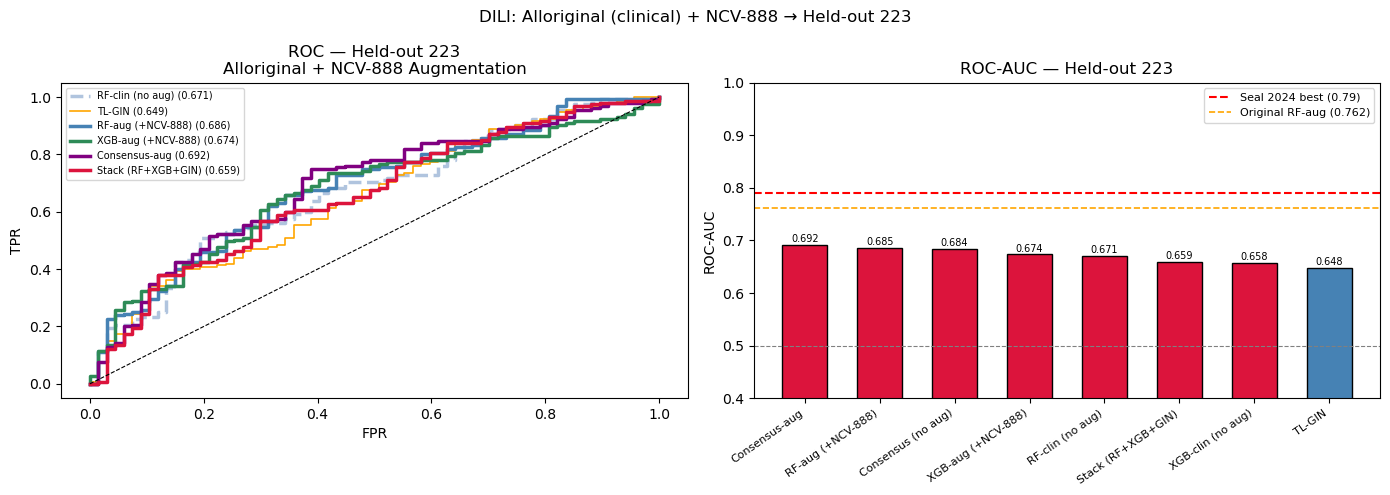

Saved -> /Users/yaminichitikela/Desktop/qsar casepase/liver/dili_alloriginal_ncv888_to_223.png


In [24]:
summary_rows = []
for name, prob in [
    ('RF-clin (no aug)',    base_probs['RF-clin']),
    ('XGB-clin (no aug)',   base_probs['XGB-clin']),
    ('TL-GIN',             p_gin),
    ('Consensus (no aug)', base_probs['Consensus']),
    ('RF-aug (+NCV-888)',  p_rf_aug),
    ('XGB-aug (+NCV-888)', p_xgb_aug),
    ('Consensus-aug',      p_cons_aug),
    ('Stack (RF+XGB+GIN)', p_stack),
]:
    r = evaluate(y_held, prob, name)
    summary_rows.append({k: r[k] for k in METRIC_COLS})

df_summary = pd.DataFrame(summary_rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print('=== Final Results on Held-out 223 ===')
print(df_summary[METRIC_COLS].to_string(index=False))

print(f'\n{"="*72}')
print('BENCHMARK vs Seal et al. 2024')
print(f'{"="*72}')
published = [
    ('Seal 2024 — ECFP4 only',               0.54),
    ('Seal 2024 — Mordred + physicochemical', 0.61),
    ('Seal 2024 — proxy-DILI + PK',           0.67),
    ('Seal 2024 — DILIPredictor (best)',       0.79),
]
for name, auc in published:
    print(f'  {name:<50} AUC={auc:.4f}  [published]')
print('-'*64)
for _, row in df_summary.iterrows():
    print(f'  {row["Model"]:<50} AUC={row["ROC-AUC"]:.4f}  [this work]')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
COLORS = {
    'RF-clin (no aug)':   'lightsteelblue',
    'XGB-clin (no aug)':  'lightgreen',
    'TL-GIN':             'orange',
    'Consensus (no aug)': 'gray',
    'RF-aug (+NCV-888)':  'steelblue',
    'XGB-aug (+NCV-888)': 'seagreen',
    'Consensus-aug':      'purple',
    'Stack (RF+XGB+GIN)': 'crimson',
}
for name, prob in [
    ('RF-clin (no aug)',   base_probs['RF-clin']),
    ('TL-GIN',            p_gin),
    ('RF-aug (+NCV-888)', p_rf_aug),
    ('XGB-aug (+NCV-888)',p_xgb_aug),
    ('Consensus-aug',     p_cons_aug),
    ('Stack (RF+XGB+GIN)',p_stack),
]:
    fpr, tpr, _ = roc_curve(y_held, prob)
    auc = roc_auc_score(y_held, prob)
    lw = 2.5 if 'aug' in name.lower() or 'Stack' in name else 1.2
    ls = '--' if 'no aug' in name else '-'
    axes[0].plot(fpr, tpr, label=f'{name} ({auc:.3f})',
                 color=COLORS.get(name,'gray'), lw=lw, linestyle=ls)
axes[0].plot([0,1],[0,1],'k--',lw=0.8)
axes[0].set_title('ROC — Held-out 223\nAlloriginal + NCV-888 Augmentation')
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].legend(fontsize=7)

x = np.arange(len(df_summary))
axes[1].bar(x, df_summary['ROC-AUC'], 0.6,
            color=['crimson' if ('aug' in m.lower() or 'Stack' in m) else 'steelblue'
                   for m in df_summary['Model']],
            edgecolor='black')
axes[1].axhline(0.79,  color='red',    linestyle='--', lw=1.5, label='Seal 2024 best (0.79)')
axes[1].axhline(0.762, color='orange', linestyle='--', lw=1.2, label='Original RF-aug (0.762)')
axes[1].axhline(0.5,   color='gray',   linestyle='--', lw=0.8)
axes[1].set_title('ROC-AUC — Held-out 223'); axes[1].set_ylabel('ROC-AUC'); axes[1].set_ylim(0.4,1.0)
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_summary['Model'], rotation=35, ha='right', fontsize=8)
for i, v in enumerate(df_summary['ROC-AUC']):
    axes[1].text(i, v+0.005, f'{v:.3f}', ha='center', fontsize=7)
axes[1].legend(fontsize=8)

plt.suptitle('DILI: Alloriginal (clinical) + NCV-888 → Held-out 223', fontsize=12)
plt.tight_layout()
out_path = f'{BASE}/liver/dili_alloriginal_ncv888_to_223.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {out_path}')

In [25]:
import pandas as pd
from rdkit import Chem

def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except:
        return None

all_orig = pd.read_csv('/Users/yaminichitikela/Desktop/qsar casepase/liver/Alloriginaldata_19911.csv')
proxy    = pd.read_csv('/Users/yaminichitikela/Desktop/qsar casepase/liver/proxy-DILI_dataset_12133.csv')

set_all   = set(all_orig['smiles_r'].apply(canonicalize).dropna())
set_proxy = set(proxy['smiles_r'].apply(canonicalize).dropna())

print(f"Alloriginaldata : {len(set_all):,}")
print(f"proxy-DILI      : {len(set_proxy):,}")
print(f"Common          : {len(set_all & set_proxy):,}")



Alloriginaldata : 13,788
proxy-DILI      : 7,873
Common          : 6,104


In [26]:
proxy


,smiles_r,TOXICITY,Source_rank,Source,Data
0,CN(Cc1ccc(C(C)(C)C)cc1)Cc1cccc2ccccc12,1,3,"human hepatotoxicity, hepatobiallry, literaty...",LivTox
1,COc1cc2c(cc1OC)CC(=O)N(CCCN(C)CC1Cc3cc(OC)c(OC...,1,3,"human hepatotoxicity, hepatobiallry, literaty...",LivTox
2,CC(C)(C)CC(=O)OCC(=O)C1(O)CCC2C3CC=C4CC(=O)C=C...,1,3,"human hepatotoxicity, hepatobiallry, literaty...",LivTox
3,CNc1ccccc1,1,3,"human hepatotoxicity, hepatobiallry, literaty...",LivTox
4,CCC1NC(=O)c2cc(S(N)(=O)=O)c(Cl)cc2N1,1,3,"human hepatotoxicity, hepatobiallry, literaty...",LivTox
...,...,...,...,...,...
12128,CC(C)C(Oc1ccc(CNC(=O)C2CCN(C(=O)CC(N)Cc3c(F)c(...,0,16,Reactive Metabolite Mazzolari et al,LivTox
12129,O=C1CC(c2ccc(O)cc2)Oc2ccccc21,0,16,Reactive Metabolite Mazzolari et al,LivTox
12130,CCCCSP(=O)(SCCCC)SCCCC,0,16,Reactive Metabolite Mazzolari et al,LivTox
12131,O=C1CC(c2ccccc2)Oc2ccccc21,0,16,Reactive Metabolite Mazzolari et al,LivTox


---
## Step 12 — GNN-GAT: Transfer Learning (Pretrain on Assays → Fine-tune on Clinical)

Graph Attention Network encoder with 4-head attention as a direct parallel to TL-GIN.  
Same pipeline: pretrain on ~307K assay compounds → gradual-unfreezing fine-tune on clinical data.  
Two variants mirror the RF/XGB setup:
- **TL-GAT (no aug)** — fine-tuned on clinical-only (identical to TL-GIN baseline)
- **TL-GAT-aug (+NCV-888)** — fine-tuned on clinical + NCV-888 augmentation

In [27]:
from torch_geometric.nn import GATConv

class GATEncoder(nn.Module):
    """Multi-head GAT encoder — same interface as GNNEncoder (GIN)."""
    def __init__(self, in_dim, hidden=256, n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden     = hidden
        self.dropout    = dropout
        self.input_proj = nn.Linear(in_dim, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            # concat=True → n_heads * (hidden//n_heads) = hidden (dimension preserved)
            self.convs.append(GATConv(hidden, hidden // n_heads, heads=n_heads,
                                      dropout=dropout, concat=True))
            self.bns.append(nn.BatchNorm1d(hidden))

    def forward(self, data):
        x, ei, batch = data.x, data.edge_index, data.batch
        h = self.input_proj(x)
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.elu(conv(h, ei)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

gat_encoder    = GATEncoder(ATOM_DIM, hidden=HIDDEN, n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gat_head_assay = ClassHead(hidden=HIDDEN).to(DEVICE)
print(f'GATEncoder (4-head, {N_LAYERS} layers)  params: {sum(p.numel() for p in gat_encoder.parameters()):,}')
print(f'GNNEncoder (GIN) for reference         params: {sum(p.numel() for p in encoder.parameters()):,}')

GATEncoder (4-head, 4 layers)  params: 273,408
GNNEncoder (GIN) for reference         params: 534,528


In [28]:
# ── Pretrain GAT on ~307K assay compounds ───────────────────────────────────
pos_w_assay_gat = torch.tensor(
    [(y_assay_all[idx_ap_tr] == 0).sum() / max((y_assay_all[idx_ap_tr] == 1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_gat_pre  = nn.BCEWithLogitsLoss(pos_weight=pos_w_assay_gat)
opt_gat_pre   = torch.optim.Adam(
    list(gat_encoder.parameters()) + list(gat_head_assay.parameters()), lr=1e-3)
sched_gat_pre = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_gat_pre, patience=5, factor=0.5)

best_gat_pre_auc, best_gat_enc_state, no_imp_gat_pre = 0, None, 0

print('=== Stage 1: Pretraining GAT on assay compounds ===')
for ep in range(PRETRAIN_EPOCHS):
    gat_encoder.train(); gat_head_assay.train()
    for batch in assay_tr_ld:
        batch = batch.to(DEVICE)
        opt_gat_pre.zero_grad()
        crit_gat_pre(gat_head_assay(gat_encoder(batch)), batch.y).backward()
        opt_gat_pre.step()
    pre_probs, pre_labels = get_probs(gat_encoder, gat_head_assay, assay_va_ld, DEVICE)
    va_auc = roc_auc_score(pre_labels, pre_probs)
    sched_gat_pre.step(1 - va_auc)
    if va_auc > best_gat_pre_auc:
        best_gat_pre_auc   = va_auc
        best_gat_enc_state = copy.deepcopy(gat_encoder.state_dict())
        no_imp_gat_pre     = 0
    else:
        no_imp_gat_pre += 1
        if no_imp_gat_pre >= PRETRAIN_PATIENCE:
            print(f'  Early stop ep {ep+1}  best_val={best_gat_pre_auc:.4f}'); break
    if (ep+1) % 10 == 0:
        print(f'  Ep {ep+1:3d}  val_AUC={va_auc:.4f}  best={best_gat_pre_auc:.4f}')

gat_encoder.load_state_dict(best_gat_enc_state)
print(f'GAT pretraining done. Best val AUC = {best_gat_pre_auc:.4f}')

=== Stage 1: Pretraining GAT on assay compounds ===
  Ep  10  val_AUC=0.8489  best=0.8489
  Ep  20  val_AUC=0.8681  best=0.8681
  Ep  30  val_AUC=0.8746  best=0.8747
  Ep  40  val_AUC=0.8816  best=0.8821
  Ep  50  val_AUC=0.8862  best=0.8876
GAT pretraining done. Best val AUC = 0.8876


In [29]:
# ── Fine-tune GAT-clin on clinical data only (no augmentation) ───────────────
gat_dili_head = ClassHead(hidden=HIDDEN).to(DEVICE)
crit_gat_ft   = nn.BCEWithLogitsLoss(pos_weight=pos_w_clin)

gat_best_auc, gat_best_enc, gat_best_head = 0.0, None, None

def ft_gat_phase(phase_name, trainable_params, n_epochs, lr, patience=8):
    global gat_best_auc, gat_best_enc, gat_best_head
    opt   = torch.optim.Adam(trainable_params, lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    no_imp = 0
    print(f'\n--- {phase_name}  (lr={lr:.0e}, max {n_epochs} ep) ---')
    for ep in range(n_epochs):
        gat_encoder.train(); gat_dili_head.train()
        for batch in clin_tr_ld:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            crit_gat_ft(gat_dili_head(gat_encoder(batch)), batch.y).backward()
            opt.step()
        va_p, va_l = get_probs(gat_encoder, gat_dili_head, clin_va_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > gat_best_auc:
            gat_best_auc  = va_auc
            gat_best_enc  = copy.deepcopy(gat_encoder.state_dict())
            gat_best_head = copy.deepcopy(gat_dili_head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience: break
    print(f'    best_global_val_AUC={gat_best_auc:.4f}')

# Phase 0: freeze encoder, train head only
for p in gat_encoder.parameters():  p.requires_grad = False
for p in gat_dili_head.parameters(): p.requires_grad = True
ft_gat_phase('Phase 0 — head only (encoder frozen)', list(gat_dili_head.parameters()), 20, 1e-3)

# Phase 1: unfreeze top layer
for p in gat_encoder.convs[3].parameters(): p.requires_grad = True
for p in gat_encoder.bns[3].parameters():   p.requires_grad = True
ft_gat_phase('Phase 1 — unfreeze convs[3]',
    [p for p in list(gat_encoder.parameters())+list(gat_dili_head.parameters()) if p.requires_grad],
    20, 5e-4)

# Phase 2
for p in gat_encoder.convs[2].parameters(): p.requires_grad = True
for p in gat_encoder.bns[2].parameters():   p.requires_grad = True
ft_gat_phase('Phase 2 — unfreeze convs[2]',
    [p for p in list(gat_encoder.parameters())+list(gat_dili_head.parameters()) if p.requires_grad],
    20, 1e-4)

# Phase 3
for p in gat_encoder.convs[1].parameters(): p.requires_grad = True
for p in gat_encoder.bns[1].parameters():   p.requires_grad = True
ft_gat_phase('Phase 3 — unfreeze convs[1]',
    [p for p in list(gat_encoder.parameters())+list(gat_dili_head.parameters()) if p.requires_grad],
    15, 5e-5)

# Phase 4: unfreeze all
for p in gat_encoder.parameters(): p.requires_grad = True
ft_gat_phase('Phase 4 — unfreeze all',
    list(gat_encoder.parameters())+list(gat_dili_head.parameters()), 15, 1e-5)

gat_encoder.load_state_dict(gat_best_enc)
gat_dili_head.load_state_dict(gat_best_head)
print(f'\nGAT-clin fine-tuning done. Best val AUC = {gat_best_auc:.4f}')


--- Phase 0 — head only (encoder frozen)  (lr=1e-03, max 20 ep) ---
    best_global_val_AUC=0.6995

--- Phase 1 — unfreeze convs[3]  (lr=5e-04, max 20 ep) ---
    best_global_val_AUC=0.7072

--- Phase 2 — unfreeze convs[2]  (lr=1e-04, max 20 ep) ---
    best_global_val_AUC=0.7072

--- Phase 3 — unfreeze convs[1]  (lr=5e-05, max 15 ep) ---
    best_global_val_AUC=0.7072

--- Phase 4 — unfreeze all  (lr=1e-05, max 15 ep) ---
    best_global_val_AUC=0.7079

GAT-clin fine-tuning done. Best val AUC = 0.7079


In [30]:
# ── Fine-tune GAT-aug (clinical + NCV-888) ──────────────────────────────────
# Fresh encoder from best pretrained weights
gat_enc_aug  = GATEncoder(ATOM_DIM, hidden=HIDDEN, n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gat_enc_aug.load_state_dict(best_gat_enc_state)
gat_head_aug = ClassHead(hidden=HIDDEN).to(DEVICE)

gat_aug_graphs = g_c_tr + ncv_graphs_list          # clinical-train + NCV-888
gat_aug_loader = DataLoader(gat_aug_graphs, batch_size=64, shuffle=True)

sw_aug_gat   = (y_aug == 0).sum() / max((y_aug == 1).sum(), 1)
pos_w_aug    = torch.tensor([sw_aug_gat], dtype=torch.float).to(DEVICE)
crit_gat_aug = nn.BCEWithLogitsLoss(pos_weight=pos_w_aug)

gat_aug_best_auc, gat_aug_best_enc, gat_aug_best_head = 0.0, None, None

def ft_gat_aug_phase(phase_name, trainable_params, n_epochs, lr, patience=8):
    global gat_aug_best_auc, gat_aug_best_enc, gat_aug_best_head
    opt   = torch.optim.Adam(trainable_params, lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    no_imp = 0
    print(f'\n--- {phase_name}  (lr={lr:.0e}, max {n_epochs} ep) ---')
    for ep in range(n_epochs):
        gat_enc_aug.train(); gat_head_aug.train()
        for batch in gat_aug_loader:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            crit_gat_aug(gat_head_aug(gat_enc_aug(batch)), batch.y).backward()
            opt.step()
        va_p, va_l = get_probs(gat_enc_aug, gat_head_aug, clin_va_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > gat_aug_best_auc:
            gat_aug_best_auc  = va_auc
            gat_aug_best_enc  = copy.deepcopy(gat_enc_aug.state_dict())
            gat_aug_best_head = copy.deepcopy(gat_head_aug.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience: break
    print(f'    best_global_val_AUC={gat_aug_best_auc:.4f}')

for p in gat_enc_aug.parameters():  p.requires_grad = False
for p in gat_head_aug.parameters(): p.requires_grad = True
ft_gat_aug_phase('Phase 0 — head only (encoder frozen)', list(gat_head_aug.parameters()), 20, 1e-3)

for p in gat_enc_aug.convs[3].parameters(): p.requires_grad = True
for p in gat_enc_aug.bns[3].parameters():   p.requires_grad = True
ft_gat_aug_phase('Phase 1 — unfreeze convs[3]',
    [p for p in list(gat_enc_aug.parameters())+list(gat_head_aug.parameters()) if p.requires_grad],
    20, 5e-4)

for p in gat_enc_aug.convs[2].parameters(): p.requires_grad = True
for p in gat_enc_aug.bns[2].parameters():   p.requires_grad = True
ft_gat_aug_phase('Phase 2 — unfreeze convs[2]',
    [p for p in list(gat_enc_aug.parameters())+list(gat_head_aug.parameters()) if p.requires_grad],
    20, 1e-4)

for p in gat_enc_aug.convs[1].parameters(): p.requires_grad = True
for p in gat_enc_aug.bns[1].parameters():   p.requires_grad = True
ft_gat_aug_phase('Phase 3 — unfreeze convs[1]',
    [p for p in list(gat_enc_aug.parameters())+list(gat_head_aug.parameters()) if p.requires_grad],
    15, 5e-5)

for p in gat_enc_aug.parameters(): p.requires_grad = True
ft_gat_aug_phase('Phase 4 — unfreeze all',
    list(gat_enc_aug.parameters())+list(gat_head_aug.parameters()), 15, 1e-5)

gat_enc_aug.load_state_dict(gat_aug_best_enc)
gat_head_aug.load_state_dict(gat_aug_best_head)
print(f'\nGAT-aug fine-tuning done. Best val AUC = {gat_aug_best_auc:.4f}')


--- Phase 0 — head only (encoder frozen)  (lr=1e-03, max 20 ep) ---
    best_global_val_AUC=0.6958

--- Phase 1 — unfreeze convs[3]  (lr=5e-04, max 20 ep) ---
    best_global_val_AUC=0.7036

--- Phase 2 — unfreeze convs[2]  (lr=1e-04, max 20 ep) ---
    best_global_val_AUC=0.7050

--- Phase 3 — unfreeze convs[1]  (lr=5e-05, max 15 ep) ---
    best_global_val_AUC=0.7080

--- Phase 4 — unfreeze all  (lr=1e-05, max 15 ep) ---
    best_global_val_AUC=0.7085

GAT-aug fine-tuning done. Best val AUC = 0.7085


=== GAT Results on Held-out 223 ===
Model                                      AUC    CCR   Sens   Spec     MCC
----------------------------------------------------------------------
TL-GAT (no aug)                         0.6656  62.8%  65.8%  59.7%  0.2373
TL-GAT-aug (+NCV-888)                   0.6605  62.2%  67.7%  56.7%  0.2295
Consensus-4way (RF+XGB+GIN+GAT)         0.6899  64.0%  63.9%  64.2%  0.2590

=== Full Summary: All Models on Held-out 223 ===
                          Model  Sensitivity  Specificity  CCR  ROC-AUC  PR-AUC    MCC     F1
     Consensus-aug (RF+XGB+GIN)         61.9         64.2 63.1   0.6919  0.8195 0.2405 0.6982
Consensus-4way (RF+XGB+GIN+GAT)         63.9         64.2 64.0   0.6899  0.8191 0.2590 0.7122
              RF-aug (+NCV-888)         53.5         74.6 64.1   0.6855  0.8222 0.2600 0.6510
             Consensus (no aug)         61.3         64.2 62.7   0.6843  0.8103 0.2344 0.6934
             XGB-aug (+NCV-888)         65.8         64.2 65.0   0.67

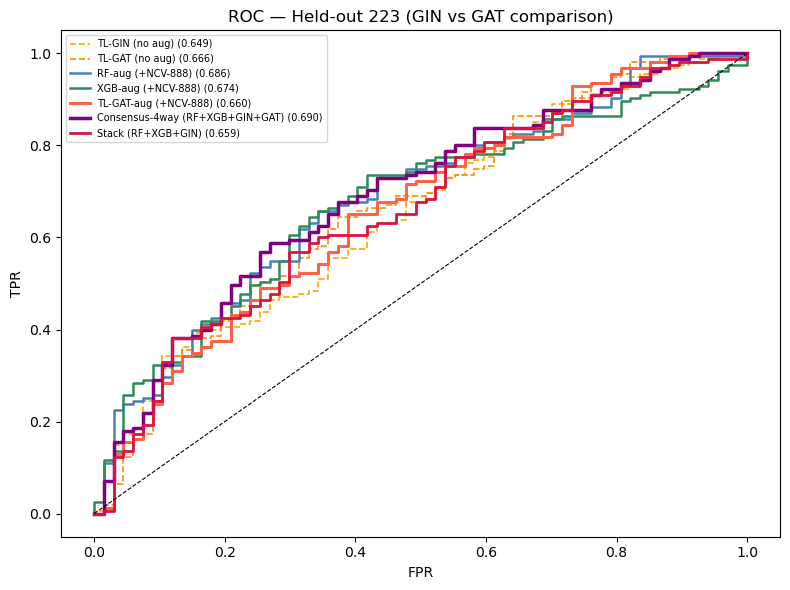

Saved -> /Users/yaminichitikela/Desktop/qsar casepase/liver/dili_gat_comparison.png


In [31]:
# ── GAT Evaluation on held-out 223 + Updated Full Summary ───────────────────
print('=== GAT Results on Held-out 223 ===')
print(f'{"Model":<38}  {"AUC":>6}  {"CCR":>5}  {"Sens":>5}  {"Spec":>5}  {"MCC":>6}')
print('-'*70)

p_gat, _     = get_probs(gat_encoder,  gat_dili_head, held_loader, DEVICE)
r_gat        = evaluate(y_held, p_gat,     'TL-GAT (no aug)')
p_gat_aug, _ = get_probs(gat_enc_aug,  gat_head_aug,  held_loader, DEVICE)
r_gat_aug    = evaluate(y_held, p_gat_aug, 'TL-GAT-aug (+NCV-888)')

for r in [r_gat, r_gat_aug]:
    print(f'{r["Model"]:<38}  {r["ROC-AUC"]:>6.4f}  {r["CCR"]:>4.1f}%  '
          f'{r["Sensitivity"]:>4.1f}%  {r["Specificity"]:>4.1f}%  {r["MCC"]:>6.4f}')

# 4-way consensus: RF-aug + XGB-aug + GIN + GAT-aug
p_cons_4way = np.mean([p_rf_aug, p_xgb_aug, p_gin, p_gat_aug], axis=0)
r_cons_4way = evaluate(y_held, p_cons_4way, 'Consensus-4way (RF+XGB+GIN+GAT)')
print(f'{r_cons_4way["Model"]:<38}  {r_cons_4way["ROC-AUC"]:>6.4f}  {r_cons_4way["CCR"]:>4.1f}%  '
      f'{r_cons_4way["Sensitivity"]:>4.1f}%  {r_cons_4way["Specificity"]:>4.1f}%  {r_cons_4way["MCC"]:>6.4f}')

# ── Updated full summary ─────────────────────────────────────────────────────
print('\n=== Full Summary: All Models on Held-out 223 ===')
all_rows = []
for name, prob in [
    ('RF-clin (no aug)',                 base_probs['RF-clin']),
    ('XGB-clin (no aug)',                base_probs['XGB-clin']),
    ('TL-GIN (no aug)',                  p_gin),
    ('TL-GAT (no aug)',                  p_gat),
    ('Consensus (no aug)',               base_probs['Consensus']),
    ('RF-aug (+NCV-888)',                p_rf_aug),
    ('XGB-aug (+NCV-888)',               p_xgb_aug),
    ('TL-GAT-aug (+NCV-888)',            p_gat_aug),
    ('Consensus-aug (RF+XGB+GIN)',       p_cons_aug),
    ('Consensus-4way (RF+XGB+GIN+GAT)', p_cons_4way),
    ('Stack (RF+XGB+GIN)',               p_stack),
]:
    r = evaluate(y_held, prob, name)
    all_rows.append({k: r[k] for k in METRIC_COLS})

df_all = pd.DataFrame(all_rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print(df_all[METRIC_COLS].to_string(index=False))

# ── ROC plot ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
PLOT_MODELS = [
    ('TL-GIN (no aug)',                  p_gin,        'orange',   '--', 1.2),
    ('TL-GAT (no aug)',                  p_gat,        'darkorange','--', 1.2),
    ('RF-aug (+NCV-888)',                p_rf_aug,     'steelblue','-',  1.8),
    ('XGB-aug (+NCV-888)',               p_xgb_aug,    'seagreen', '-',  1.8),
    ('TL-GAT-aug (+NCV-888)',            p_gat_aug,    'tomato',   '-',  2.2),
    ('Consensus-4way (RF+XGB+GIN+GAT)', p_cons_4way,  'purple',   '-',  2.5),
    ('Stack (RF+XGB+GIN)',               p_stack,      'crimson',  '-',  2.0),
]
for name, prob, color, ls, lw in PLOT_MODELS:
    fpr, tpr, _ = roc_curve(y_held, prob)
    auc = roc_auc_score(y_held, prob)
    ax.plot(fpr, tpr, label=f'{name} ({auc:.3f})', color=color, linestyle=ls, lw=lw)
ax.plot([0,1],[0,1],'k--', lw=0.8)
ax.set_title('ROC — Held-out 223 (GIN vs GAT comparison)')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(fontsize=7)
plt.tight_layout()
out_gat = f'{BASE}/liver/dili_gat_comparison.png'
plt.savefig(out_gat, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {out_gat}')

---
## Step 13 — Graph Transformers: Graphormer & GraphGPS

Two-stage transfer learning (mirrors GIN/GAT pipeline, but pretrains on DILI data instead of assays):
- **Stage 1 — Pretraining**: train on Alloriginal ~19K molecules **minus held-out-223** (DILI labels as supervision)  
- **Stage 2 — Fine-tuning**: fine-tune on clinical split only / clinical + NCV-888 augmentation  
- **Test**: held-out 223 (never seen during training or pretraining)

**Graphormer** — `TransformerConv` + degree (centrality) encoding + bond features  
**GraphGPS** — Laplacian eigenvector PE + `GINEConv` (bond-aware) + global `MultiheadAttention`


In [32]:
from torch_geometric.nn import TransformerConv, GINEConv, GPSConv
from torch_geometric.utils import degree as pyg_degree, get_laplacian, to_dense_adj

PE_DIM   = 8   # Laplacian PE dimension for GraphGPS
BOND_DIM = 6   # edge_attr dimension (already in all graphs)

# ── Laplacian PE ─────────────────────────────────────────────────────────────
def compute_laplacian_pe(data, k=PE_DIM):
    n = data.num_nodes
    if n <= 2:
        return torch.zeros(n, k)
    ei, ew = get_laplacian(data.edge_index, normalization='sym', num_nodes=n)
    L = to_dense_adj(ei, edge_attr=ew, max_num_nodes=n).squeeze(0).numpy()
    try:
        import numpy.linalg as nla
        _, vecs = nla.eigh(L)
        num_take = min(k, n - 1)
        pe = torch.from_numpy(vecs[:, 1:1+num_take]).float()
        if pe.shape[1] < k:
            pe = F.pad(pe, (0, k - pe.shape[1]))
    except Exception:
        pe = torch.zeros(n, k)
    return pe

def add_pe(graph_list):
    from torch_geometric.data import Data as TGData
    out = []
    for d in graph_list:
        pe = compute_laplacian_pe(d)
        out.append(TGData(x=d.x, edge_index=d.edge_index,
                          edge_attr=d.edge_attr, y=d.y, pe=pe))
    return out

# ── Graphormer encoder ────────────────────────────────────────────────────────
class GraphormerEncoder(nn.Module):
    """TransformerConv + centrality (degree) encoding + bond features."""
    def __init__(self, in_dim, hidden=256, n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        self.input_proj = nn.Linear(in_dim, hidden)
        self.degree_emb = nn.Embedding(100, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        head_dim   = hidden // n_heads
        for _ in range(n_layers):
            self.convs.append(
                TransformerConv(hidden, head_dim, heads=n_heads,
                                edge_dim=BOND_DIM, concat=True,
                                dropout=dropout, beta=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        h   = self.input_proj(x)
        deg = pyg_degree(ei[0], num_nodes=x.size(0)).long().clamp(max=99)
        h   = F.relu(h + self.degree_emb(deg))
        for conv, bn in zip(self.convs, self.bns):
            h = bn(F.gelu(conv(h, ei, ea)))
            h = F.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

# ── GraphGPS encoder ──────────────────────────────────────────────────────────
class GraphGPSEncoder(nn.Module):
    """Laplacian PE + GINEConv (bond-aware) + global MultiheadAttention."""
    def __init__(self, in_dim, hidden=256, pe_dim=PE_DIM,
                 n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        self.input_proj = nn.Linear(in_dim, hidden)
        self.pe_proj    = nn.Linear(pe_dim, hidden)
        self.gps_layers = nn.ModuleList()
        for _ in range(n_layers):
            mlp  = nn.Sequential(nn.Linear(hidden, hidden*2), nn.GELU(),
                                 nn.Linear(hidden*2, hidden))
            conv = GINEConv(mlp, edge_dim=BOND_DIM)
            gps  = GPSConv(channels=hidden, conv=conv, heads=n_heads,
                           dropout=dropout, norm='layer_norm',
                           attn_type='multihead')
            self.gps_layers.append(gps)

    def forward(self, data):
        x, ei, ea, batch, pe = (data.x, data.edge_index, data.edge_attr,
                                 data.batch, data.pe)
        h = F.relu(self.input_proj(x) + self.pe_proj(pe))
        h = F.dropout(h, p=self.dropout, training=self.training)
        for gps in self.gps_layers:
            h = gps(h, ei, batch, edge_attr=ea)
        return global_mean_pool(h, batch)

# ── Generic training helper ───────────────────────────────────────────────────
def train_gt_model(encoder, head, train_loader, val_loader, criterion,
                   max_epochs=100, lr=1e-3, patience=15, label=''):
    torch.manual_seed(SEED)
    opt   = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=5, factor=0.5)
    best_auc, best_enc, best_head, no_imp = 0.0, None, None, 0
    print(f'Training {label}  (max {max_epochs} ep, patience {patience}) ...')
    for ep in range(max_epochs):
        encoder.train(); head.train()
        for batch in train_loader:
            batch = batch.to(DEVICE)
            opt.zero_grad()
            criterion(head(encoder(batch)), batch.y).backward()
            opt.step()
        va_p, va_l = get_probs(encoder, head, val_loader, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        sched.step(1 - va_auc)
        if va_auc > best_auc:
            best_auc  = va_auc
            best_enc  = copy.deepcopy(encoder.state_dict())
            best_head = copy.deepcopy(head.state_dict())
            no_imp    = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                print(f'  Early stop ep {ep+1}  best_val={best_auc:.4f}'); break
        if (ep+1) % 25 == 0:
            print(f'  Ep {ep+1:3d}  val_AUC={va_auc:.4f}  best={best_auc:.4f}')
    encoder.load_state_dict(best_enc)
    head.load_state_dict(best_head)
    print(f'  Done. Best val AUC = {best_auc:.4f}')
    return best_auc

print(f'GraphormerEncoder params : {sum(p.numel() for p in GraphormerEncoder(ATOM_DIM,HIDDEN,4,N_LAYERS).parameters()):,}')
print(f'GraphGPSEncoder  params  : {sum(p.numel() for p in GraphGPSEncoder(ATOM_DIM,HIDDEN,PE_DIM,4,N_LAYERS).parameters()):,}')


GraphormerEncoder params : 1,095,680
GraphGPSEncoder  params  : 3,177,728


In [37]:
# Build pretraining set: alloriginal minus held-out-223
# held_smiles is defined in cell 10; alldata is the full 19,911-row dataframe
print('Building pretraining graph set (Alloriginal minus held-out-223)...')
pretrain_df = alldata[~alldata['csmi'].isin(held_smiles)].reset_index(drop=True)
pretrain_df = pretrain_df[['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'})
_, _, y_pretrain, pretrain_graphs = build_features(pretrain_df,
    'Pretraining (Alloriginal minus held-out-223)')

pretrain_loader = DataLoader(pretrain_graphs, batch_size=64, shuffle=True)

# Add Laplacian PE for GraphGPS
print('\nAdding Laplacian PE for GraphGPS...')
gps_pretrain = add_pe(pretrain_graphs)
gps_c_tr     = add_pe(g_c_tr)
gps_c_va     = add_pe(g_c_va)
gps_held     = add_pe(held_graphs)
gps_ncv      = add_pe(ncv_graphs_list)

gps_pretrain_loader = DataLoader(gps_pretrain, batch_size=64, shuffle=True)
gps_clin_tr_ld      = DataLoader(gps_c_tr,     batch_size=64, shuffle=True)
gps_clin_va_ld      = DataLoader(gps_c_va,     batch_size=64)
gps_held_loader     = DataLoader(gps_held,     batch_size=64)

print(f'Pretraining (regular) : {len(pretrain_graphs):,}  DILI+={y_pretrain.sum():,}')
print(f'GPS pretrain          : {len(gps_pretrain):,}')
print(f'GPS clin train        : {len(gps_c_tr):,}')
print(f'GPS clin val          : {len(gps_c_va):,}')
print(f'GPS NCV-888           : {len(gps_ncv):,}')
print(f'GPS held-out-223      : {len(gps_held):,}')


Building pretraining graph set (Alloriginal minus held-out-223)...
Pretraining (Alloriginal minus held-out-223): 13,609  DILI+=4,650  DILI-=8,959

Adding Laplacian PE for GraphGPS...
Pretraining (regular) : 13,609  DILI+=4,650
GPS pretrain          : 13,609
GPS clin train        : 10,320
GPS clin val          : 1,290
GPS NCV-888           : 874
GPS held-out-223      : 222


In [38]:
# ── Graphormer: 2-stage transfer learning ───────────────────────────────────
y_aug_gt     = np.concatenate([y_c_tr, y_ncv])
pos_w_aug_gt = torch.tensor(
    [(y_aug_gt==0).sum() / max((y_aug_gt==1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
grph_aug_loader = DataLoader(g_c_tr + ncv_graphs_list, batch_size=64, shuffle=True)

# Stage 1 — pretrain on alloriginal minus held-out-223 (~19K)
pos_w_pt = torch.tensor(
    [(y_pretrain==0).sum() / max((y_pretrain==1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_pt = nn.BCEWithLogitsLoss(pos_weight=pos_w_pt)

grph_pre_enc  = GraphormerEncoder(ATOM_DIM, hidden=HIDDEN, n_heads=4, n_layers=N_LAYERS).to(DEVICE)
grph_pre_head = ClassHead(hidden=HIDDEN).to(DEVICE)
print('=== Graphormer Stage 1 — Pretrain on Alloriginal minus held-out-223 ===')
train_gt_model(grph_pre_enc, grph_pre_head,
               pretrain_loader, clin_va_ld, crit_pt,
               max_epochs=80, patience=15, lr=1e-3, label='Graphormer-pretrain')
grph_pretrain_state = copy.deepcopy(grph_pre_enc.state_dict())

# Stage 2a — fine-tune on clinical only (warm-start from pretraining)
crit_clin_grph = nn.BCEWithLogitsLoss(pos_weight=pos_w_clin)
graphormer_enc  = GraphormerEncoder(ATOM_DIM, hidden=HIDDEN, n_heads=4, n_layers=N_LAYERS).to(DEVICE)
graphormer_enc.load_state_dict(grph_pretrain_state)
graphormer_head = ClassHead(hidden=HIDDEN).to(DEVICE)
print('\n=== Graphormer Stage 2a — Fine-tune clinical only ===')
train_gt_model(graphormer_enc, graphormer_head,
               clin_tr_ld, clin_va_ld, crit_clin_grph,
               max_epochs=60, patience=12, lr=3e-4, label='Graphormer-clin')

# Stage 2b — fine-tune on clinical + NCV-888 (warm-start from pretraining)
crit_aug_grph   = nn.BCEWithLogitsLoss(pos_weight=pos_w_aug_gt)
graphormer_enc_aug  = GraphormerEncoder(ATOM_DIM, hidden=HIDDEN, n_heads=4, n_layers=N_LAYERS).to(DEVICE)
graphormer_enc_aug.load_state_dict(grph_pretrain_state)
graphormer_head_aug = ClassHead(hidden=HIDDEN).to(DEVICE)
print('\n=== Graphormer Stage 2b — Fine-tune augmented (clinical + NCV-888) ===')
train_gt_model(graphormer_enc_aug, graphormer_head_aug,
               grph_aug_loader, clin_va_ld, crit_aug_grph,
               max_epochs=60, patience=12, lr=3e-4, label='Graphormer-aug')


=== Graphormer Stage 1 — Pretrain on Alloriginal minus held-out-223 ===
Training Graphormer-pretrain  (max 80 ep, patience 15) ...
  Ep  25  val_AUC=0.6482  best=0.6519
  Early stop ep 49  best_val=0.6620
  Done. Best val AUC = 0.6620

=== Graphormer Stage 2a — Fine-tune clinical only ===
Training Graphormer-clin  (max 60 ep, patience 12) ...
  Ep  25  val_AUC=0.6591  best=0.6637
  Early stop ep 28  best_val=0.6637
  Done. Best val AUC = 0.6637

=== Graphormer Stage 2b — Fine-tune augmented (clinical + NCV-888) ===
Training Graphormer-aug  (max 60 ep, patience 12) ...
  Ep  25  val_AUC=0.6643  best=0.6741
  Ep  50  val_AUC=0.6741  best=0.6790
  Early stop ep 52  best_val=0.6790
  Done. Best val AUC = 0.6790


0.6789932185991657

In [39]:
# ── GraphGPS: 2-stage transfer learning ─────────────────────────────────────
gps_aug_loader = DataLoader(gps_c_tr + gps_ncv, batch_size=64, shuffle=True)

# Stage 1 — pretrain on alloriginal minus held-out-223 (~19K)
pos_w_pt_gps = torch.tensor(
    [(y_pretrain==0).sum() / max((y_pretrain==1).sum(), 1)],
    dtype=torch.float).to(DEVICE)
crit_pt_gps = nn.BCEWithLogitsLoss(pos_weight=pos_w_pt_gps)

gps_pre_enc  = GraphGPSEncoder(ATOM_DIM, hidden=HIDDEN, pe_dim=PE_DIM,
                                n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gps_pre_head = ClassHead(hidden=HIDDEN).to(DEVICE)
print('=== GraphGPS Stage 1 — Pretrain on Alloriginal minus held-out-223 ===')
train_gt_model(gps_pre_enc, gps_pre_head,
               gps_pretrain_loader, gps_clin_va_ld, crit_pt_gps,
               max_epochs=80, patience=15, lr=1e-3, label='GraphGPS-pretrain')
gps_pretrain_state = copy.deepcopy(gps_pre_enc.state_dict())

# Stage 2a — fine-tune on clinical only (warm-start from pretraining)
crit_clin_gps = nn.BCEWithLogitsLoss(pos_weight=pos_w_clin)
gps_enc  = GraphGPSEncoder(ATOM_DIM, hidden=HIDDEN, pe_dim=PE_DIM,
                            n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gps_enc.load_state_dict(gps_pretrain_state)
gps_head = ClassHead(hidden=HIDDEN).to(DEVICE)
print('\n=== GraphGPS Stage 2a — Fine-tune clinical only ===')
train_gt_model(gps_enc, gps_head,
               gps_clin_tr_ld, gps_clin_va_ld, crit_clin_gps,
               max_epochs=60, patience=12, lr=3e-4, label='GraphGPS-clin')

# Stage 2b — fine-tune on clinical + NCV-888 (warm-start from pretraining)
crit_aug_gps = nn.BCEWithLogitsLoss(pos_weight=pos_w_aug_gt)
gps_enc_aug  = GraphGPSEncoder(ATOM_DIM, hidden=HIDDEN, pe_dim=PE_DIM,
                                n_heads=4, n_layers=N_LAYERS).to(DEVICE)
gps_enc_aug.load_state_dict(gps_pretrain_state)
gps_head_aug = ClassHead(hidden=HIDDEN).to(DEVICE)
print('\n=== GraphGPS Stage 2b — Fine-tune augmented (clinical + NCV-888) ===')
train_gt_model(gps_enc_aug, gps_head_aug,
               gps_aug_loader, gps_clin_va_ld, crit_aug_gps,
               max_epochs=60, patience=12, lr=3e-4, label='GraphGPS-aug')


=== GraphGPS Stage 1 — Pretrain on Alloriginal minus held-out-223 ===
Training GraphGPS-pretrain  (max 80 ep, patience 15) ...
  Ep  25  val_AUC=0.6143  best=0.6143
  Ep  50  val_AUC=0.6489  best=0.6512
  Ep  75  val_AUC=0.6698  best=0.6749
  Done. Best val AUC = 0.6749

=== GraphGPS Stage 2a — Fine-tune clinical only ===
Training GraphGPS-clin  (max 60 ep, patience 12) ...
  Ep  25  val_AUC=0.6853  best=0.6876
  Early stop ep 40  best_val=0.6922
  Done. Best val AUC = 0.6922

=== GraphGPS Stage 2b — Fine-tune augmented (clinical + NCV-888) ===
Training GraphGPS-aug  (max 60 ep, patience 12) ...
  Ep  25  val_AUC=0.6780  best=0.6811
  Early stop ep 32  best_val=0.6811
  Done. Best val AUC = 0.6811


0.6811048987703934

=== Graph Transformer Results on Held-out 223 ===
Model                                          AUC    CCR   Sens   Spec     MCC
---------------------------------------------------------------------------
TL-Graphormer (no aug)                      0.6377  57.8%  76.8%  38.8%  0.1594
TL-Graphormer-aug (+NCV)                    0.6501  59.3%  85.8%  32.8%  0.2147
TL-GraphGPS (no aug)                        0.6328  59.6%  34.2%  85.1%  0.1962
TL-GraphGPS-aug (+NCV)                      0.6533  59.4%  36.8%  82.1%  0.1871

Consensus-6way (+NCV)                       0.6979  66.5%  65.8%  67.2%  0.3048

=== Full Summary: All Models on Held-out 223 ===
                          Model  Sensitivity  Specificity  CCR  ROC-AUC  PR-AUC    MCC     F1
          Consensus-6way (+NCV)         65.8         67.2 66.5   0.6979  0.8208 0.3048 0.7312
     Consensus-aug (RF+XGB+GIN)         61.9         64.2 63.1   0.6919  0.8195 0.2405 0.6982
Consensus-4way (RF+XGB+GIN+GAT)         63.9         64.2 64.

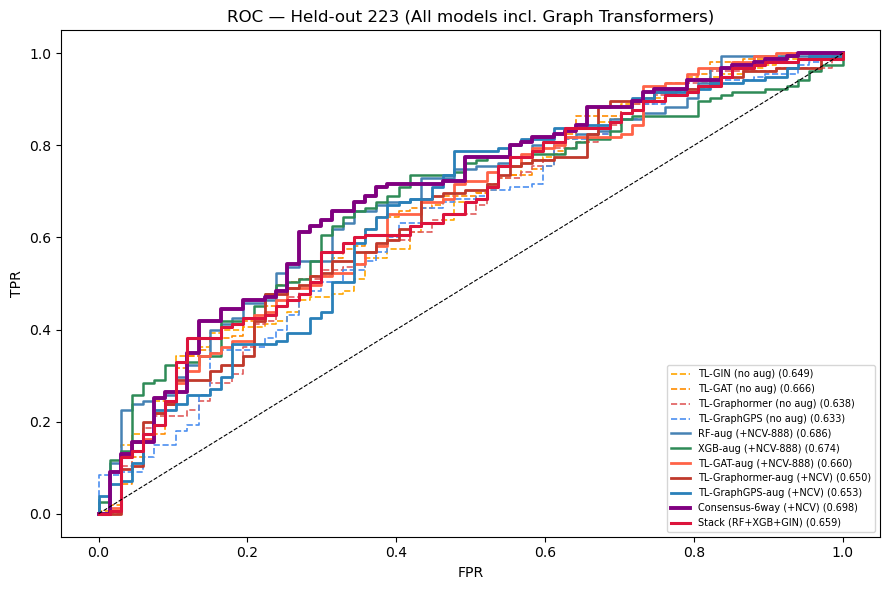

Saved -> /Users/yaminichitikela/Desktop/qsar casepase/liver/dili_gt_comparison.png


In [40]:
# ── GT Evaluation on held-out 223 ────────────────────────────────────────────
print('=== Graph Transformer Results on Held-out 223 ===')
print(f'{"Model":<42}  {"AUC":>6}  {"CCR":>5}  {"Sens":>5}  {"Spec":>5}  {"MCC":>6}')
print('-'*75)

p_grph,     _ = get_probs(graphormer_enc,     graphormer_head,     held_loader,     DEVICE)
p_grph_aug, _ = get_probs(graphormer_enc_aug, graphormer_head_aug, held_loader,     DEVICE)
p_gps,      _ = get_probs(gps_enc,            gps_head,            gps_held_loader, DEVICE)
p_gps_aug,  _ = get_probs(gps_enc_aug,        gps_head_aug,        gps_held_loader, DEVICE)

for name, prob in [
    ('TL-Graphormer (no aug)',     p_grph),
    ('TL-Graphormer-aug (+NCV)',   p_grph_aug),
    ('TL-GraphGPS (no aug)',       p_gps),
    ('TL-GraphGPS-aug (+NCV)',     p_gps_aug),
]:
    r = evaluate(y_held, prob, name)
    print(f'{r["Model"]:<42}  {r["ROC-AUC"]:>6.4f}  {r["CCR"]:>4.1f}%  '
          f'{r["Sensitivity"]:>4.1f}%  {r["Specificity"]:>4.1f}%  {r["MCC"]:>6.4f}')

# 6-way consensus (all augmented): RF + XGB + GIN + GAT + Graphormer + GraphGPS
p_cons_6way = np.mean([p_rf_aug, p_xgb_aug, p_gin, p_gat_aug,
                        p_grph_aug, p_gps_aug], axis=0)
r_c6 = evaluate(y_held, p_cons_6way, 'Consensus-6way (+NCV)')
print(f'\n{r_c6["Model"]:<42}  {r_c6["ROC-AUC"]:>6.4f}  {r_c6["CCR"]:>4.1f}%  '
      f'{r_c6["Sensitivity"]:>4.1f}%  {r_c6["Specificity"]:>4.1f}%  {r_c6["MCC"]:>6.4f}')

# ── Full summary ──────────────────────────────────────────────────────────────
print('\n=== Full Summary: All Models on Held-out 223 ===')
all_rows = []
for name, prob in [
    ('RF-clin (no aug)',                   base_probs['RF-clin']),
    ('XGB-clin (no aug)',                  base_probs['XGB-clin']),
    ('TL-GIN (no aug)',                    p_gin),
    ('TL-GAT (no aug)',                    p_gat),
    ('TL-Graphormer (no aug)',             p_grph),
    ('TL-GraphGPS (no aug)',               p_gps),
    ('Consensus (no aug)',                 base_probs['Consensus']),
    ('RF-aug (+NCV-888)',                  p_rf_aug),
    ('XGB-aug (+NCV-888)',                 p_xgb_aug),
    ('TL-GAT-aug (+NCV-888)',              p_gat_aug),
    ('TL-Graphormer-aug (+NCV)',           p_grph_aug),
    ('TL-GraphGPS-aug (+NCV)',             p_gps_aug),
    ('Consensus-aug (RF+XGB+GIN)',         p_cons_aug),
    ('Consensus-4way (RF+XGB+GIN+GAT)',    p_cons_4way),
    ('Consensus-6way (+NCV)',              p_cons_6way),
    ('Stack (RF+XGB+GIN)',                 p_stack),
]:
    r = evaluate(y_held, prob, name)
    all_rows.append({k: r[k] for k in METRIC_COLS})

df_all = (pd.DataFrame(all_rows)
          .sort_values('ROC-AUC', ascending=False)
          .reset_index(drop=True))
print(df_all[METRIC_COLS].to_string(index=False))

# ── ROC plot ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
for name, prob, color, ls, lw in [
    ('TL-GIN (no aug)',               p_gin,        'orange',    '--', 1.2),
    ('TL-GAT (no aug)',               p_gat,        'darkorange','--', 1.2),
    ('TL-Graphormer (no aug)',        p_grph,       '#e05c5c',   '--', 1.2),
    ('TL-GraphGPS (no aug)',          p_gps,        '#4c8ff0',   '--', 1.2),
    ('RF-aug (+NCV-888)',             p_rf_aug,     'steelblue', '-',  1.8),
    ('XGB-aug (+NCV-888)',            p_xgb_aug,    'seagreen',  '-',  1.8),
    ('TL-GAT-aug (+NCV-888)',         p_gat_aug,    'tomato',    '-',  2.0),
    ('TL-Graphormer-aug (+NCV)',      p_grph_aug,   '#c0392b',   '-',  2.0),
    ('TL-GraphGPS-aug (+NCV)',        p_gps_aug,    '#2980b9',   '-',  2.0),
    ('Consensus-6way (+NCV)',         p_cons_6way,  'purple',    '-',  2.8),
    ('Stack (RF+XGB+GIN)',            p_stack,      'crimson',   '-',  2.2),
]:
    fpr, tpr, _ = roc_curve(y_held, prob)
    auc = roc_auc_score(y_held, prob)
    ax.plot(fpr, tpr, label=f'{name} ({auc:.3f})', color=color, linestyle=ls, lw=lw)
ax.plot([0,1],[0,1],'k--', lw=0.8)
ax.set_title('ROC — Held-out 223 (All models incl. Graph Transformers)')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
out_gt = f'{BASE}/liver/dili_gt_comparison.png'
plt.savefig(out_gt, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved -> {out_gt}')
